# Activity 5.01: Clustering Sales Data Using K-Means

**Course activity:** Applied Artificial Intelligence Workshop  
**Goal:** Group products with similar weekly sales patterns using K-Means clustering.

## What this notebook does
1. Loads the Sales Transactions Dataset Weekly from the book's public GitHub repository.
2. Inspects the data and separates the 52 weekly sales columns from product identifiers and precomputed normalized columns.
3. Uses the 52 normalized weekly values as clustering features.
4. Fits the required K-Means model with **8 clusters** and `random_state=8`.
5. Adds the cluster label to each product and summarizes average weekly sales by cluster.
6. Compares a few values of *k* with inertia and silhouette score as an additional diagnostic.

K-Means is an unsupervised learning method. The cluster numbers are labels, not rankings; cluster 0 is not necessarily better or worse than cluster 1.

In [1]:
# Import the libraries used in this activity.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# Make tables and plots easier to read in the notebook.
pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 120)

## 1. Load the dataset

The source file contains one row per product. Columns named `W0` through `W51` are weekly sales, and columns named `Normalized 0` through `Normalized 51` are normalized versions of those weekly values. `Product_Code`, `MIN`, and `MAX` are not weekly sales features.

The dataset is loaded directly from the UCI Machine Learning Repository URL supplied for this assignment, so the notebook can run in Google Colab without a manual upload.

In [2]:
file_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00396/Sales_Transactions_Dataset_Weekly.csv"

df = pd.read_csv(file_url)

print("Dataset shape (rows, columns):", df.shape)
display(df.head())

Dataset shape (rows, columns): (811, 107)


,Product_Code,W0,W1,W2,W3,W4,W5,...,Normalized 45,Normalized 46,Normalized 47,Normalized 48,Normalized 49,Normalized 50,Normalized 51
0,P1,11,12,10,8,13,12,...,0.39,0.50,0.00,0.22,0.17,0.11,0.39
1,P2,7,6,3,2,7,1,...,0.10,0.10,0.40,0.50,0.10,0.60,0.00
2,P3,7,11,8,9,10,8,...,0.18,0.36,0.45,1.00,0.45,0.45,0.36
3,P4,12,8,13,5,9,6,...,0.12,0.24,0.35,0.71,0.35,0.29,0.35
4,P5,8,5,13,11,6,7,...,0.60,0.20,0.20,0.13,0.53,0.33,0.40


## 2. Inspect and validate the columns

We expect a product identifier, 52 weekly sales columns, summary columns, and 52 normalized columns. Checking these names before modeling helps catch changes in the source file.

In [3]:
weekly_columns = [f"W{i}" for i in range(52)]
normalized_columns = [f"Normalized {i}" for i in range(52)]

missing_weekly = [col for col in weekly_columns if col not in df.columns]
missing_normalized = [col for col in normalized_columns if col not in df.columns]

print("Rows/products:", len(df))
print("Weekly columns found:", len(weekly_columns) - len(missing_weekly))
print("Normalized columns found:", len(normalized_columns) - len(missing_normalized))
print("Missing weekly columns:", missing_weekly)
print("Missing normalized columns:", missing_normalized)

display(df[["Product_Code"] + weekly_columns[:5] + normalized_columns[:5]].head())

Rows/products: 811
Weekly columns found: 52
Normalized columns found: 52
Missing weekly columns: []
Missing normalized columns: []


,Product_Code,W0,W1,W2,W3,W4,Normalized 0,Normalized 1,Normalized 2,Normalized 3,Normalized 4
0,P1,11,12,10,8,13,0.44,0.50,0.39,0.28,0.56
1,P2,7,6,3,2,7,0.70,0.60,0.30,0.20,0.70
2,P3,7,11,8,9,10,0.36,0.73,0.45,0.55,0.64
3,P4,12,8,13,5,9,0.59,0.35,0.65,0.18,0.41
4,P5,8,5,13,11,6,0.33,0.13,0.67,0.53,0.20


## 3. Prepare the clustering features

We cluster products using the normalized weekly sales columns. Normalization reduces the effect of products having very different overall sales volumes, allowing K-Means to focus more on the shape of their weekly patterns.

We keep the original `df` unchanged so that the weekly sales columns remain available for the summary table.

In [4]:
# Convert feature columns to numeric values and handle any missing values.
X = df[normalized_columns].apply(pd.to_numeric, errors="coerce")
X = X.fillna(X.mean())

# K-Means requires numeric features and no missing values.
assert X.shape[1] == 52, "Expected 52 normalized weekly sales features."
assert not X.isna().any().any(), "Missing values remain in the feature matrix."

print("Feature matrix shape:", X.shape)
display(X.head())

Feature matrix shape: (811, 52)


,Normalized 0,Normalized 1,Normalized 2,Normalized 3,Normalized 4,Normalized 5,Normalized 6,...,Normalized 45,Normalized 46,Normalized 47,Normalized 48,Normalized 49,Normalized 50,Normalized 51
0,0.44,0.50,0.39,0.28,0.56,0.50,0.61,...,0.39,0.50,0.00,0.22,0.17,0.11,0.39
1,0.70,0.60,0.30,0.20,0.70,0.10,0.60,...,0.10,0.10,0.40,0.50,0.10,0.60,0.00
2,0.36,0.73,0.45,0.55,0.64,0.45,0.36,...,0.18,0.36,0.45,1.00,0.45,0.45,0.36
3,0.59,0.35,0.65,0.18,0.41,0.24,0.41,...,0.12,0.24,0.35,0.71,0.35,0.29,0.35
4,0.33,0.13,0.67,0.53,0.20,0.27,0.40,...,0.60,0.20,0.20,0.13,0.53,0.33,0.40


## 4. Fit K-Means with eight clusters

The activity specifies `n_clusters=8` and `random_state=8`. The fixed random state makes the initialization reproducible. `n_init=10` runs several initializations and keeps the best result.

In [5]:
kmeans = KMeans(n_clusters=8, random_state=8, n_init=10)
labels = kmeans.fit_predict(X)

# Keep the cluster label alongside each product's original information.
clustered_df = df.copy()
clustered_df["Cluster"] = labels

print("Number of clusters found:", clustered_df["Cluster"].nunique())
print("Products assigned to each cluster:")
display(clustered_df["Cluster"].value_counts().sort_index().rename("Product count").to_frame())
display(clustered_df[["Product_Code", "Cluster"]].head())

Number of clusters found: 8
Products assigned to each cluster:


,Product count
Cluster,
0,127
1,54
2,115
3,98
4,125
5,89
6,84
7,119


,Product_Code,Cluster
0,P1,7
1,P2,7
2,P3,3
3,P4,7
4,P5,7


## 5. Summarize average weekly sales by cluster

For interpretation, group the original weekly sales columns by the assigned cluster and calculate the mean for each week. Each row in this result represents a cluster; each week column shows the average sales for products assigned to that cluster.

Average weekly sales for each cluster:


,W0,W1,W2,W3,W4,W5,W6,...,W45,W46,W47,W48,W49,W50,W51
Cluster,,,,,,,,,,,,,,,
0,7.88,7.98,7.52,7.78,8.72,8.39,8.09,...,7.93,8.89,9.35,8.95,10.56,11.59,13.52
1,0.50,0.22,0.33,0.31,0.41,0.41,0.37,...,1.24,1.06,0.78,0.85,0.91,1.07,0.52
2,0.09,0.10,0.08,0.08,0.07,0.09,0.12,...,0.10,0.25,0.07,0.23,0.26,0.23,0.04
3,10.78,11.03,10.94,11.16,10.17,11.80,11.53,...,8.94,8.66,8.52,9.27,9.90,11.02,11.87
4,27.98,29.74,30.85,31.49,30.86,30.05,31.93,...,26.98,26.89,26.70,26.24,25.11,23.38,19.13
5,1.65,1.55,2.03,2.15,1.92,2.04,2.12,...,2.53,2.94,3.35,2.96,3.45,4.00,5.67
6,0.21,0.29,0.30,0.35,0.26,0.36,0.25,...,0.46,0.62,0.54,0.71,0.80,0.88,2.39
7,12.30,11.82,12.60,13.59,13.29,12.24,12.52,...,11.26,11.20,10.74,11.04,11.02,10.06,10.08


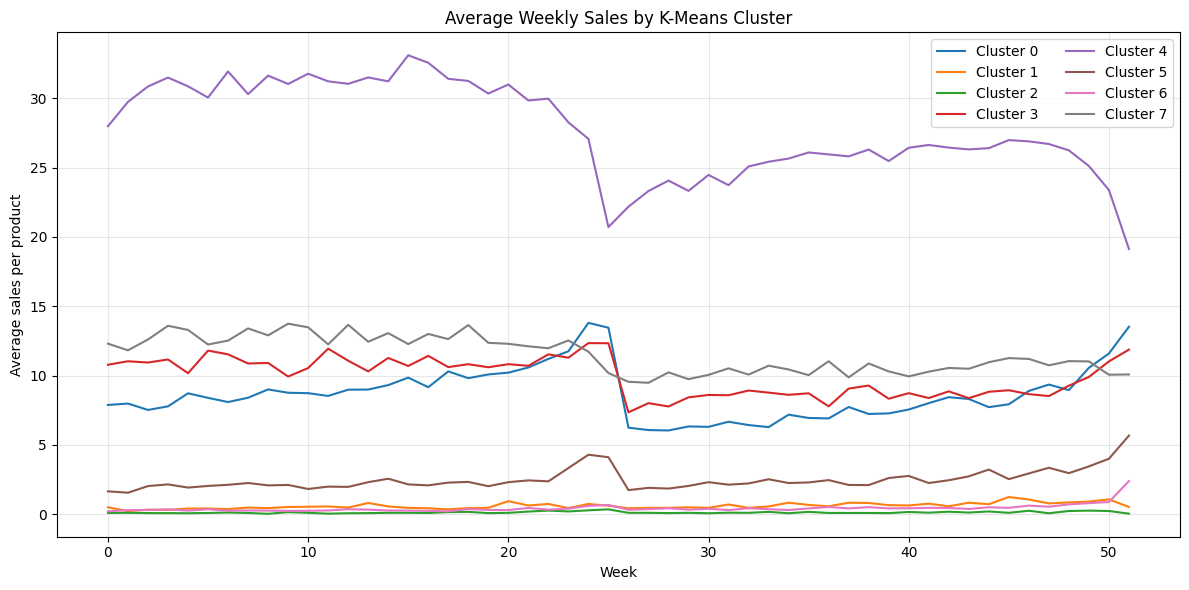

In [6]:
cluster_weekly_means = clustered_df.groupby("Cluster")[weekly_columns].mean().round(2)

print("Average weekly sales for each cluster:")
display(cluster_weekly_means)

# Plot the average weekly sales profile for each cluster.
plt.figure(figsize=(12, 6))
for cluster_id, row in cluster_weekly_means.iterrows():
    plt.plot(range(52), row.values, label=f"Cluster {cluster_id}")
plt.title("Average Weekly Sales by K-Means Cluster")
plt.xlabel("Week")
plt.ylabel("Average sales per product")
plt.legend(ncol=2)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Compare candidate numbers of clusters

The required model uses eight clusters. As an extra check, we compare several values of *k*. Inertia measures within-cluster squared distances (lower is better, but it always tends to decrease as *k* increases). Silhouette score measures how well-separated clusters are (higher is generally better). These scores are diagnostics, not proof that one value of *k* is uniquely correct.

In [7]:
# Evaluate a small range of cluster counts on the normalized weekly data.
evaluation_rows = []
for k in range(2, 11):
    candidate = KMeans(n_clusters=k, random_state=8, n_init=10)
    candidate_labels = candidate.fit_predict(X)
    evaluation_rows.append({
        "k": k,
        "inertia": candidate.inertia_,
        "silhouette_score": silhouette_score(X, candidate_labels)
    })

evaluation_df = pd.DataFrame(evaluation_rows)
display(evaluation_df.round(4))

,k,inertia,silhouette_score
0,2,2402.6697,0.2464
1,3,2271.5450,0.1075
2,4,2202.3451,0.0768
3,5,2166.6455,0.0511
4,6,2133.5194,0.0477
5,7,2115.7546,0.0431
6,8,2088.7793,0.0405
7,9,2079.0245,0.0413
8,10,2054.9410,0.0359


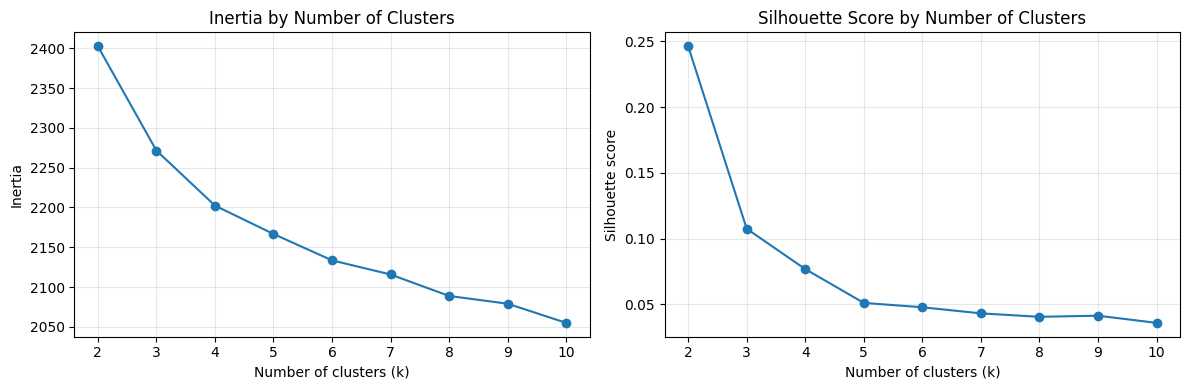

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(evaluation_df["k"], evaluation_df["inertia"], marker="o")
axes[0].set_title("Inertia by Number of Clusters")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].grid(True, alpha=0.3)

axes[1].plot(evaluation_df["k"], evaluation_df["silhouette_score"], marker="o")
axes[1].set_title("Silhouette Score by Number of Clusters")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Results and interpretation

The K-Means model assigned each product to one of eight groups based on its normalized weekly sales pattern. The `cluster_weekly_means` table and line chart summarize the average sales pattern for each group. Products in the same cluster have more similar normalized weekly patterns than products that are far apart in the feature space.

Because the dataset contains sales data but no product descriptions, the clusters cannot be assigned meaningful product-category names from this dataset alone. Cluster numbers are arbitrary. The evaluation table can help compare candidate cluster counts, while the eight-cluster result follows the activity's specified settings.

## Source

Tan, J. (2014). *Sales Transactions Weekly* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XS4Q

UCI Machine Learning Repository. (2014). *Sales Transactions Weekly* [Dataset]. https://archive.ics.uci.edu/ml/machine-learning-databases/00396/Sales_Transactions_Dataset_Weekly.csv

**Before submission:** In Google Colab, choose **Runtime → Run all** and confirm every cell completes. Then download the executed notebook as `.ipynb` and use **File → Print** (or the browser print dialog) to save a readable PDF printout. Upload the notebook and PDF to your public GitHub repository, and submit only the notebook, repository link, and PDF as your instructor requests.